Perform nested cross-validation to assess model generalization capability and avoid data leakage, providing unbiased performance estimates for highly complex classification tasks.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 800

In [4]:
treatment_duration_days = np.random.poisson(lam=14, size=n_samples).clip(1, 60)
prior_antibiotic_courses = np.random.poisson(lam=3, size=n_samples).clip(0, 10)
bacterial_load_log10 = np.random.normal(5.5, 1.2, n_samples).clip(2.0, 9.0).round(2)
immunosuppressed_status = np.random.binomial(n=1, p=0.25, size=n_samples)
patient_age = np.random.uniform(18, 85, n_samples).round(1)

In [5]:
random_noise_1 = np.random.normal(0, 1, n_samples).round(3)
random_noise_2 = np.random.uniform(0, 50, n_samples).round(2)

In [6]:
resistance_logits = (
    0.08 * (treatment_duration_days - 14)
    + 0.45 * prior_antibiotic_courses
    + 0.60 * (bacterial_load_log10 - 5.5)
    + 1.20 * immunosuppressed_status
    + 0.05 * prior_antibiotic_courses * (bacterial_load_log10 - 5.5) # Non-linear interaction
    - 3.80
)

In [7]:
probs = 1 / (1 + np.exp(-resistance_logits))
target = (probs > np.median(probs)).astype(int)

In [8]:
df_nested = pd.DataFrame({
    'treatment_duration_days': treatment_duration_days,
    'prior_antibiotic_courses': prior_antibiotic_courses,
    'bacterial_load_log10': bacterial_load_log10,
    'immunosuppressed_status': immunosuppressed_status,
    'patient_age': patient_age,
    'random_noise_1': random_noise_1,
    'random_noise_2': random_noise_2,
    'drug_resistant': target
})

In [9]:
print("Dataset Shape:", df_nested.shape)
print("Drug Resistance Class Distribution:\n", df_nested['drug_resistant'].value_counts())

Dataset Shape: (800, 8)
Drug Resistance Class Distribution:
 drug_resistant
1    400
0    400
Name: count, dtype: int64


In [10]:
import time
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import make_scorer, f1_score

In [11]:
X = df_nested.drop(columns=['drug_resistant'])
y = df_nested['drug_resistant']

In [12]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

In [13]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', HistGradientBoostingClassifier(random_state=42))
])

In [14]:
param_grid = {
    'clf__learning_rate': [0.01, 0.05, 0.1],
    'clf__max_leaf_nodes': [15, 31],
    'clf__min_samples_leaf': [10, 20],
    'clf__l2_regularization': [0.0, 1.0, 5.0]
}

In [15]:
grid_search_non_nested = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=inner_cv,
    scoring='f1',
    n_jobs=-1
)

In [16]:
t0_non_nested = time.perf_counter()
grid_search_non_nested.fit(X, y)
t1_non_nested = time.perf_counter()

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

In [17]:
optimistic_score = grid_search_non_nested.best_score_

In [18]:
grid_search_nested = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=inner_cv,
    scoring='f1',
    n_jobs=-1
)

In [19]:
t0_nested = time.perf_counter()
nested_scores = cross_val_score(
    grid_search_nested,
    X,
    y,
    cv=outer_cv,
    scoring='f1',
    n_jobs=-1
)
t1_nested = time.perf_counter()

In [20]:
unbiased_mean_score = nested_scores.mean()
unbiased_std_score = nested_scores.std()

In [21]:
print("--- Cross-Validation Benchmark Results ---")
print(f"Non-Nested CV Best F1-Score (Optimistic) : {optimistic_score:.4f} (Time: {t1_non_nested - t0_non_nested:.2f}s)")
print(f"Nested CV Mean F1-Score (Unbiased)       : {unbiased_mean_score:.4f} +/- {unbiased_std_score:.4f} (Time: {t1_nested - t0_nested:.2f}s)")
print(f"Estimated Optimistic Selection Bias      : {optimistic_score - unbiased_mean_score:+.4f}")

--- Cross-Validation Benchmark Results ---
Non-Nested CV Best F1-Score (Optimistic) : 0.9526 (Time: 13.17s)
Nested CV Mean F1-Score (Unbiased)       : 0.9499 +/- 0.0042 (Time: 18.87s)
Estimated Optimistic Selection Bias      : +0.0027


In [22]:
import matplotlib.pyplot as plt

In [23]:
outer_fold_metrics = []

In [24]:
for fold_idx, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), 1):
    X_train_fold, X_test_fold = X.iloc[train_idx], X.iloc[test_idx]
    y_train_fold, y_test_fold = y.iloc[train_idx], y.iloc[test_idx]
    
    fold_grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=inner_cv,
        scoring='f1',
        n_jobs=-1
    )
    fold_grid_search.fit(X_train_fold, y_train_fold)
    
    best_fold_model = fold_grid_search.best_estimator_
    y_pred_fold = best_fold_model.predict(X_test_fold)
    
    fold_f1 = f1_score(y_test_fold, y_pred_fold)
    outer_fold_metrics.append({
        'Outer Fold': f'Fold {fold_idx}',
        'Best Inner F1': fold_grid_search.best_score_,
        'Outer Test F1': fold_f1,
        'Selected Params': str(fold_grid_search.best_params_)
    })

In [25]:
df_outer_results = pd.DataFrame(outer_fold_metrics).set_index('Outer Fold')

In [26]:
print(df_outer_results[['Best Inner F1', 'Outer Test F1']].round(4))

            Best Inner F1  Outer Test F1
Outer Fold                              
Fold 1             0.9476         0.9434
Fold 2             0.9551         0.9494
Fold 3             0.9446         0.9500
Fold 4             0.9469         0.9500
Fold 5             0.9491         0.9565


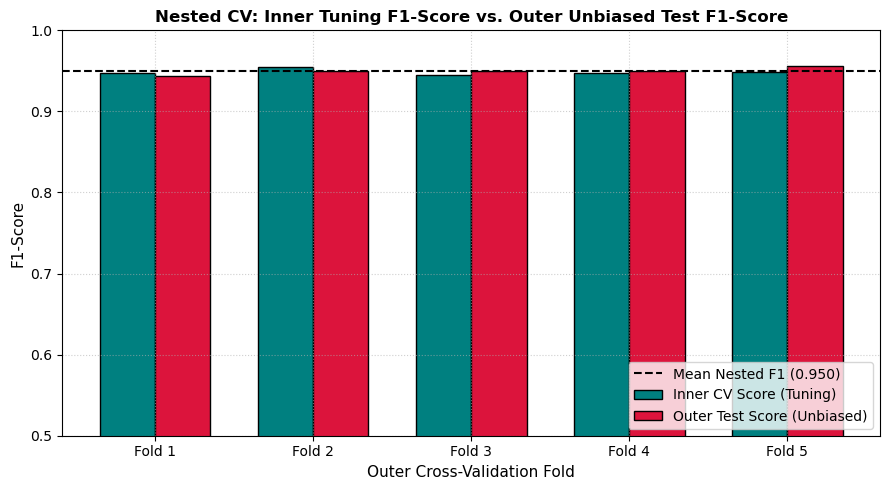

In [27]:
plt.figure(figsize=(9, 5))

x_indices = np.arange(len(df_outer_results))
width = 0.35

plt.bar(x_indices - width/2, df_outer_results['Best Inner F1'], width, label='Inner CV Score (Tuning)', color='teal', edgecolor='black')
plt.bar(x_indices + width/2, df_outer_results['Outer Test F1'], width, label='Outer Test Score (Unbiased)', color='crimson', edgecolor='black')

plt.axhline(unbiased_mean_score, color='black', linestyle='--', label=f'Mean Nested F1 ({unbiased_mean_score:.3f})')

plt.title("Nested CV: Inner Tuning F1-Score vs. Outer Unbiased Test F1-Score", fontsize=12, fontweight='bold')
plt.xlabel("Outer Cross-Validation Fold", fontsize=11)
plt.ylabel("F1-Score", fontsize=11)
plt.xticks(x_indices, df_outer_results.index)
plt.ylim(0.5, 1.0)
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()